# imports

In [37]:
!pip install torchmetrics

In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import os
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from torch.utils.data import random_split, TensorDataset, DataLoader
from torchmetrics import Accuracy
from tqdm import tqdm
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# load and prepare data

In [39]:
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

In [40]:
## get SIGNALS
BASE_PATH = '/content/drive/MyDrive/howsam_DL/week6/har_dataset/UCI HAR Dataset'


SIGNALS = []
for _, _, files in os.walk(f'{BASE_PATH}/{'test'}/Inertial Signals'):
  for file in files:
    SIGNALS.append(file.split('test')[0])
SIGNALS

['body_acc_y_',
 'body_acc_x_',
 'body_acc_z_',
 'total_acc_x_',
 'total_acc_y_',
 'total_acc_z_',
 'body_gyro_x_',
 'body_gyro_z_',
 'body_gyro_y_']

In [41]:
# /content/drive/MyDrive/howsam_DL/week6/har_dataset/UCI HAR Dataset/test/Inertial Signals/total_acc_x_test.txt

#labels: => /content/drive/MyDrive/howsam_DL/week6/har_dataset/UCI HAR Dataset/test/y_test.txt

def load_har_data(flag, base_path=BASE_PATH):
  data = []
  for signal in SIGNALS:
    file = f"{base_path}/{flag}/Inertial Signals/{signal}{flag}.txt"
    readed_file = np.loadtxt(file)
    data.append(readed_file)

    labels = f"{base_path}/{flag}/y_{flag}.txt"
    labels = np.loadtxt(labels)


    # to torch tensor
    X = torch.FloatTensor(np.array(data)).permute(1, 2, 0)
    y = torch.LongTensor(labels) - 1   # CEL is from 0 (labels starts from 1)

  return X, y

In [42]:
X_train, y_train = load_har_data('train', BASE_PATH)
X_test, y_test = load_har_data('test', BASE_PATH)

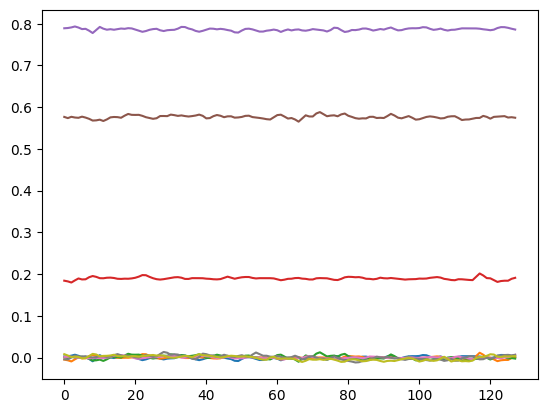

In [43]:
plt.plot(X_train[60]);

In [44]:
# /content/drive/MyDrive/howsam_DL/week6/har_dataset/UCI HAR Dataset/train/subject_train.txt

subject_path = f"{BASE_PATH}/train/subject_train.txt"
subject_train = np.loadtxt(subject_path)

gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_idx, val_idx = next(gss.split(X_train, y_train, groups=subject_train))

X_train_final, y_train_final = X_train[train_idx], y_train[train_idx]
X_valid, y_valid = X_train[val_idx], y_train[val_idx]

In [45]:
print(f"x train shape: {X_train_final.shape}")
print(f"y train shape: {y_train_final.shape}")

print()

print(f"x test shape: {X_test.shape}")
print(f"y test shape: {y_test.shape}")

print()

print(f"x valid shape: {X_valid.shape}")
print(f"y valid shape: {y_valid.shape}")

x train shape: torch.Size([6220, 128, 9])
y train shape: torch.Size([6220])

x test shape: torch.Size([2947, 128, 9])
y test shape: torch.Size([2947])

x valid shape: torch.Size([1132, 128, 9])
y valid shape: torch.Size([1132])


In [46]:
## tensor dataset & data loader to feed model

train_set = TensorDataset(X_train_final, y_train_final)
valid_set = TensorDataset(X_valid, y_valid)
test_set = TensorDataset(X_test, y_test)

# data loader
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=128, shuffle=False)
test_loader = DataLoader(test_set, batch_size=128)

# utils

In [47]:
class AverageMeter(object):
  def __init__(self):
    self.reset()

  def reset(self):
    self.val = 0
    self.count = 0
    self.sum = 0
    self.avg = 0

  def update(self, val, n=1):
    self.val = val
    self.sum += val * n
    self.count += n
    self.avg = self.sum / self.count

# functions

In [48]:
def train_one_epoch(model, data_loader, loss_fn, optimizer, epoch=None):

  model.train()

  train_loss = AverageMeter()
  train_acc = Accuracy(task = 'multiclass', num_classes = 6).to(device)

  with tqdm(data_loader, unit='batch') as tepoch:
    for inputs, targets in tepoch:
      if epoch is not None:
        tepoch.set_description(f"epoch ({epoch})")

      inputs = inputs.to(device)
      targets = targets.to(device)

      outputs = model(inputs)

      loss = loss_fn(outputs, targets)

      loss.backward()
      optimizer.step()
      optimizer.zero_grad()

      train_loss.update(loss.item())
      train_acc(outputs, targets.int())

      tepoch.set_postfix(loss=train_loss.avg,
                       acc = 100. * train_acc.compute().item())

  return model, train_loss.avg, train_acc.compute().item()

In [49]:
def validation(model, data_loader, loss_fn):

  model.eval()

  valid_loss = AverageMeter()
  valid_acc = Accuracy(task = 'multiclass', num_classes = 6).to(device)

  with torch.no_grad():
    for inputs, targets in data_loader:
      inputs = inputs.to(device)
      targets = targets.to(device)

      outputs = model(inputs)

      loss = loss_fn(outputs, targets)

      valid_loss.update(loss.item())
      valid_acc(outputs, targets.int())

  return valid_loss.avg, valid_acc.compute().item()

# model

In [50]:
model = nn.Transformer(d_model=9, nhead=3, num_encoder_layers=2,
                       num_decoder_layers=3, dim_feedforward=512,
                       dropout=0.1, activation='relu', batch_first=True)
# model

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:145: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.encoder = TransformerEncoder(


In [51]:
# model.encoder
# model.encoder.layers
# model.encoder.layers[0], model.encoder.layers[1]
# model.encoder.layers[0].self_attn
# model.decoder
# ...

In [52]:
# # costum model

# class TransformerModel(nn.Module):

#   def __init__(self, d_model, nhead, num_encoder_layers,
#                        dim_feedforward, dropout, activation, num_cls):
#     super().__init__()
#     self.encoder = nn.Transformer(d_model, nhead, num_encoder_layers,
#                                   0, dim_feedforward, dropout, activation,
#                                   batch_first=True).encoder

#     # self.enc = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward,
#     #                                       dropout, activation)
#     # self.enclayer = nn.TransformerEncoder(self.enc, 3)

#     self.fc1 = nn.Linear(d_model, num_cls)

#     self.bn1 = nn.BatchNorm1d(num_cls)

#   def forward(self, x):
#     y = self.encoder(x)
#     # y = self.ecnlayer(x)
#     y = self.fc1(y)
#     return y

In [53]:
# model = TransformerModel(9, 3, 3, 32, 0.1, 'relu', 6)

In [54]:
# xbatch, ybatch = next(iter(train_loader))
# model(xbatch).shape

In [55]:
class TransformerModel(nn.Module):

  def __init__(self, d_model, nhead, num_encoder_layers,
                       dim_feedforward, dropout, activation, num_cls):
    super().__init__()

    self.encoder = nn.Transformer(d_model, nhead, num_encoder_layers,
                                    0, dim_feedforward, dropout, activation,
                                    batch_first=True).encoder
    self.fc1 = nn.Linear(d_model, num_cls)

  def forward(self, x):
    y1 = self.encoder(x)
    # y2 = self.fc1(y1[:, -1, :]) # use one output
    y2 = self.fc1(y1).mean(dim=1) # use total output

    return y2

In [56]:
model = TransformerModel(9, 3, 5, 1024, 0.2, 'relu', 6)
model

TransformerModel(
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-4): 5 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=9, out_features=9, bias=True)
        )
        (linear1): Linear(in_features=9, out_features=1024, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=1024, out_features=9, bias=True)
        (norm1): LayerNorm((9,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((9,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
    (norm): LayerNorm((9,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (fc1): Linear(in_features=9, out_features=6, bias=True)
)

In [57]:
xbatch, ybatch = next(iter(train_loader))
model(xbatch).shape

torch.Size([64, 6])

In [58]:
class TransformerModel(nn.Module):

  def __init__(self, in_features, d_model, nhead, num_encoder_layers,
                       dim_feedforward, dropout, activation, num_cls):
    super().__init__()

    self.encoder = nn.Transformer(d_model, nhead, num_encoder_layers,
                                    0, dim_feedforward, dropout, activation,
                                    batch_first=True).encoder

    # increase features from 9 to d_model
    self.fc0 = nn.Linear(in_features, d_model)
    self.bn0 = nn.LayerNorm(d_model)

    # classifier layer
    self.fc1 = nn.Linear(d_model, num_cls)

  def forward(self, x):
    y = self.bn0(self.fc0(x)).relu()

    y = self.encoder(y)

    y = self.fc1(y[:, -1]) # use last time step (last output)


    ################################ another way is
    # y = self.bn0(self.fc0(x)).relu()
    # y = self.encoder(y)
    # y = y.mean(dim=1) # using mean to aggregate all time steps
    # y = self.fc1(y)
    #################################################

    return y

In [59]:
model = TransformerModel(9, 64, 4, 3, 512, 0.1, 'relu', 6)

xbatch, ybatch = next(iter(train_loader))
model(xbatch).shape

torch.Size([64, 6])

# loss function & optimizer

In [60]:
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.1,
                      momentum=0.9, weight_decay=1e-4)

# device

In [61]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = model.to(device)
print(device)

cuda


# best value for LR

In [ ]:
# a batch and calculate loss

xbatch, ybatch = next(iter(train_loader))
xbatch = xbatch.to(device)
ybatch = ybatch.to(device)

outputs = model(xbatch)

loss_fn(outputs, ybatch)

tensor(2.0419, device='cuda:0', grad_fn=<NllLossBackward0>)

In [ ]:
# mini loader
mini_set, _ = random_split(train_set, [500, len(train_set) - 500])
mini_loader = DataLoader(mini_set, batch_size=50)

num_epochs = 30

In [ ]:
model = TransformerModel(9, 64, 4, 2, 128, 0.1, 'relu', 6).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01,
                      momentum=0.9, weight_decay=1e-4)
for epoch in range(num_epochs):
  train_one_epoch(model, mini_loader, loss_fn, optimizer, epoch)

epoch (29): 100%|██████████| 10/10 [00:00<00:00, 87.10batch/s, acc=87.2, loss=0.298]


In [ ]:
# best lr
num_epochs = 4

for lr in [0.001, 0.005, 0.01, 0.05, 0.1]:
  print(f"lr is {lr}")

  model = TransformerModel(9, 64, 4, 2, 128, 0.1, 'relu', 6).to(device)
  loss_fn = nn.CrossEntropyLoss()
  optimizer = optim.SGD(model.parameters(), lr=lr,
                        momentum=0.9, weight_decay=1e-4)

  for epoch in range(num_epochs):
    train_one_epoch(model, mini_loader, loss_fn, optimizer, epoch)
  print()

lr is 0.001


epoch (3): 100%|██████████| 10/10 [00:00<00:00, 87.71batch/s, acc=48.4, loss=1.38]



lr is 0.005


epoch (3): 100%|██████████| 10/10 [00:00<00:00, 90.02batch/s, acc=59.8, loss=0.933]



lr is 0.01


epoch (3): 100%|██████████| 10/10 [00:00<00:00, 93.37batch/s, acc=69.4, loss=0.727]



lr is 0.05


epoch (3): 100%|██████████| 10/10 [00:00<00:00, 91.76batch/s, acc=65.6, loss=0.695]



lr is 0.1


epoch (3): 100%|██████████| 10/10 [00:00<00:00, 92.47batch/s, acc=52.2, loss=0.954]

# train whole dataset

In [68]:
model = TransformerModel(9, 64, 4, 2, 128, 0.1, 'relu', 6).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.05,
                      momentum=0.9, weight_decay=1e-4)

In [69]:
train_loss_hist = []
train_acc_hist = []

valid_loss_hist = []
valid_acc_hist = []

counter = 0
best_loss_valid = torch.inf

In [70]:
num_epochs = 20

for epoch in range(num_epochs):
  _, train_loss, train_acc = train_one_epoch(model, train_loader,
                                             loss_fn, optimizer, epoch)

  valid_loss, valid_acc = validation(model, valid_loader, loss_fn)

  print(f"validation loss is: {valid_loss:.3}")

  train_loss_hist.append(train_loss)
  train_acc_hist.append(train_acc)

  valid_loss_hist.append(valid_loss)
  valid_acc_hist.append(valid_acc)

  if valid_loss < best_loss_valid:
    best_loss_valid = valid_loss
    torch.save(model.state_dict(), 'trasformer_model.pt')
    print('model saved !')

  print()

  counter += 1

epoch (0): 100%|██████████| 98/98 [00:01<00:00, 76.77batch/s, acc=57.9, loss=0.964]


validation loss is: 0.585
model saved !



epoch (1): 100%|██████████| 98/98 [00:01<00:00, 83.90batch/s, acc=73.8, loss=0.567]


validation loss is: 0.406
model saved !



epoch (2): 100%|██████████| 98/98 [00:01<00:00, 83.42batch/s, acc=85.9, loss=0.356]


validation loss is: 0.325
model saved !



... (30 outputs left out)

epoch (18): 100%|██████████| 98/98 [00:01<00:00, 75.80batch/s, acc=94.6, loss=0.124]


validation loss is: 0.207



epoch (19): 100%|██████████| 98/98 [00:01<00:00, 71.83batch/s, acc=95, loss=0.116]


validation loss is: 0.106



# plot

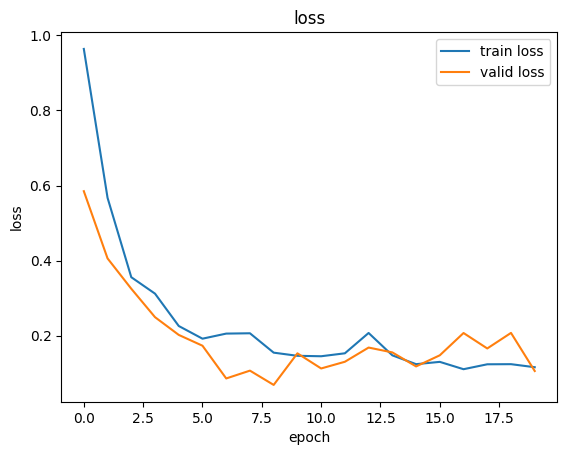

In [72]:
plt.plot(range(counter), train_loss_hist, label = 'train loss')
plt.plot(range(counter), valid_loss_hist, label = 'valid loss')

plt.title('loss')
plt.xlabel('epoch')
plt.ylabel('loss')

plt.legend()
plt.show()

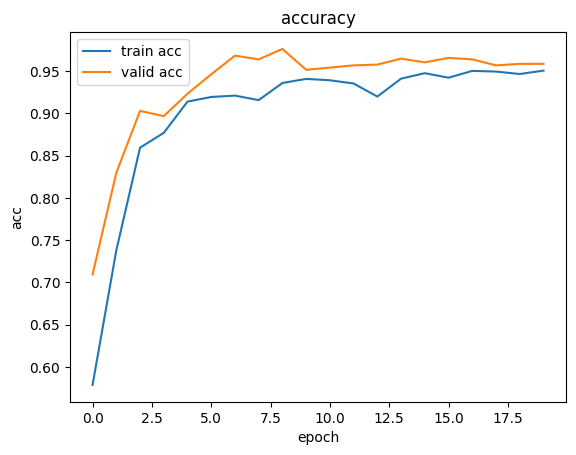

In [73]:
plt.plot(range(counter), train_acc_hist, label = 'train acc')
plt.plot(range(counter), valid_acc_hist, label = 'valid acc')

plt.title('accuracy')
plt.xlabel('epoch')
plt.ylabel('acc')

plt.legend()
plt.show()

# load model & test

In [76]:
model = TransformerModel(9, 64, 4, 2, 128, 0.1, 'relu', 6).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.05,
                      momentum=0.9, weight_decay=1e-4)

In [79]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.load_state_dict(torch.load('trasformer_model.pt', map_location=device))

model = model.to(device)
model.eval()

TransformerModel(
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
    (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (fc0): Linear(in_features=9, out_features=64, bias=True)
  (bn0): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (fc1): Linear(in_features=64, out_features=6, bias=

In [80]:
############################ test ################################

def test_model(model, test_loader, loss_fn, device):

    model.eval()

    test_loss = AverageMeter()
    test_acc = AverageMeter()

    y_true = []
    y_pred = []

    with torch.no_grad():

        for inputs, targets in test_loader:

            inputs = inputs.to(device)
            targets = targets.to(device)

            # Forward
            outputs = model(inputs)

            # Loss
            loss = loss_fn(outputs, targets)
            test_loss.update(loss.item(), inputs.size(0))

            # Predictions
            predictions = torch.argmax(outputs, dim=1)

            # Accuracy
            correct = (predictions == targets).sum().item()
            accuracy = correct / targets.size(0)

            test_acc.update(accuracy, inputs.size(0))

            # Store predictions and actual labels
            y_true.extend(targets.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    print(f"Test Loss: {test_loss.avg:.4f}")
    print(f"Test Accuracy: {test_acc.avg:.4f}")

    return test_loss.avg, test_acc.avg, y_true, y_pred

In [81]:
test_loss, test_acc, ytrue, ypred = test_model(model, test_loader, loss_fn, device)
test_loss, test_acc

Test Loss: 0.2904
Test Accuracy: 0.8948


(0.29044598070249456, 0.8948082796063793)

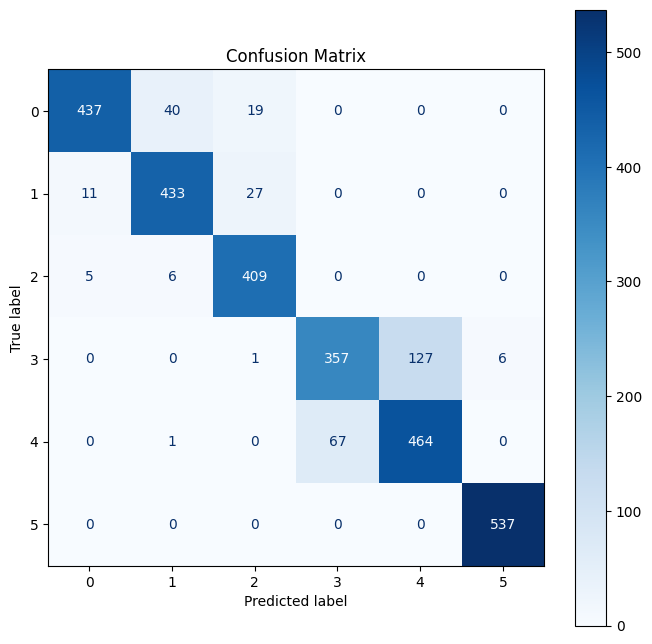

In [83]:
# Compute and plot confusion matrix
cm = confusion_matrix(ytrue, ypred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title('Confusion Matrix')
plt.show()